# Functions

In [ ]:
#imports

import os
import sys
from pathlib import Path
import json
import numpy as np
import joblib
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable


# Ensure 'src' is in the path for modular imports
src_path = Path('../src').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

    
# Import custom modules from src
from physics_base import generate_boson_base
from square_geometry import get_node_mapping
from processing import compute_metrics, get_formatted_counts, load_and_merge_jobs, extract_loop_currents_exp, compute_pair_probabilities_with_uncertainty
from plotting import plot_orbit_distribution, plot_symmetry_delta_p_correlation, plot_conditional_density_row, plot_lattice_graph, plot_current_profile, plot_exp_vs_noiseless_scatter
from kapit_mueller import kapit_mueller_J_matrix
from square_geometry import gridGraph
from utils import load_something

    

# Plotting

In [2]:
# File and directory configuration
file_dict = {
    "2h":"KM_4x4_L_nn_010_2h_p3_50_20260711_012241",
    "0h_long":"KM_4x4_L_nn_0111_center_p4_46_20260717_032456",
    "0h_short":"KM_4x4_L_nn_011_center_p3_64_20260718_171556",
}

base_data_dir = Path("../results_data")

## 2 holes

In [20]:
filename_2h = file_dict["2h"]
dir_path = base_data_dir / filename_2h

opt_data_2h = load_something(filename_2h, directory=dir_path)

job_name_list = ["DD_4ms_sym_v1",'DD_4ms_sym_v2'] #real
#job_name_list = ['run_z_basis'] #simulated
result_list = [joblib.load(os.path.join(dir_path, f"job_result_{job_name}.pkl")) for job_name in job_name_list]
counts_2h = get_formatted_counts(result_list, sum_pubs=False, sum_results=True)

tgt_info_2h = opt_data_2h['tgt_info']
Ly, Lx = tgt_info_2h['dims']
vList_2h, _ = generate_boson_base(tgt_info_2h['N'], Ly * Lx, 1)
nodes_sorted, _ = get_node_mapping(Ly, Lx) 

<class 'qiskit.primitives.containers.primitive_result.PrimitiveResult'>


In [21]:
# 3. Process Metrics Safely
metrics_2h = compute_metrics(
    counts_input=counts_2h, 
    psi_tgt=opt_data_2h['psi_tgt'], 
    psi_result=opt_data_2h['psi_result'], 
    vList=vList_2h,
    nodes_sorted=nodes_sorted, 
    Ly=Ly, Lx=Lx, 
    symmetry_preset='2h'
)
shots_2h = sum([sum(c.values()) for c in counts_2h])

--- Post-Selection Analysis ---
Evaluated across 8 layout(s)/result(s) separately.
Target Particle Count: 3
Total Shots Attempted: 80000
Total Shots Passed Post-Selection: 27661
Fraction of valid states: 0.3458 (34.58%)
--------------------------------


## N=4, no holes

In [22]:
USE_SHORT_0H = False
if not USE_SHORT_0H:
    #long, 0.95 fid
    filename_0h = file_dict["0h_long"]
    job_name_list = ["c0111_s46_DD_4ms_sym_v2",'c0111_s46_DD_4ms_sym_v1']
    print("Using the LONG protocol")
else:
    #short, 0.89 fid
    filename_0h = file_dict["0h_short"]
    job_name_list = ["c011_s64_DD_4ms_sym_v2",'c011_s64_DD_4ms_sym_v1']
    print("Using the SHORT protocol")

Using the LONG protocol


In [23]:
dir_path = base_data_dir / filename_0h

opt_data_0h = load_something(filename_0h, directory=dir_path)

result_list = [joblib.load(os.path.join(dir_path, f"job_result_{job_name}.pkl")) for job_name in job_name_list]
counts = get_formatted_counts(result_list)
counts_0h = get_formatted_counts(result_list, sum_pubs=False, sum_results=True)

tgt_info_0h = opt_data_0h['tgt_info']
Ly, Lx = tgt_info_0h['dims']

vList, _ = generate_boson_base(tgt_info_0h['N'], Ly * Lx, 1)
vList_0h, _ = generate_boson_base(tgt_info_0h['N'], Ly * Lx, 1)
nodes_sorted, _ = get_node_mapping(Ly, Lx) 

<class 'qiskit.primitives.containers.primitive_result.PrimitiveResult'>
<class 'qiskit.primitives.containers.primitive_result.PrimitiveResult'>


In [24]:
# 3. Process Metrics Safely
metrics_0h = compute_metrics(
    counts_input=counts_0h, 
    psi_tgt=opt_data_0h['psi_tgt'], 
    psi_result=opt_data_0h['psi_result'], 
    vList=vList_0h,
    nodes_sorted=nodes_sorted, 
    Ly=Ly, Lx=Lx, 
    symmetry_preset='0h'
)

shots_0h = sum([sum(c.values()) for c in counts_0h])

--- Post-Selection Analysis ---
Evaluated across 8 layout(s)/result(s) separately.
Target Particle Count: 4
Total Shots Attempted: 60000
Total Shots Passed Post-Selection: 19965
Fraction of valid states: 0.3327 (33.27%)
--------------------------------


## Run above

In [25]:
# run above

## together

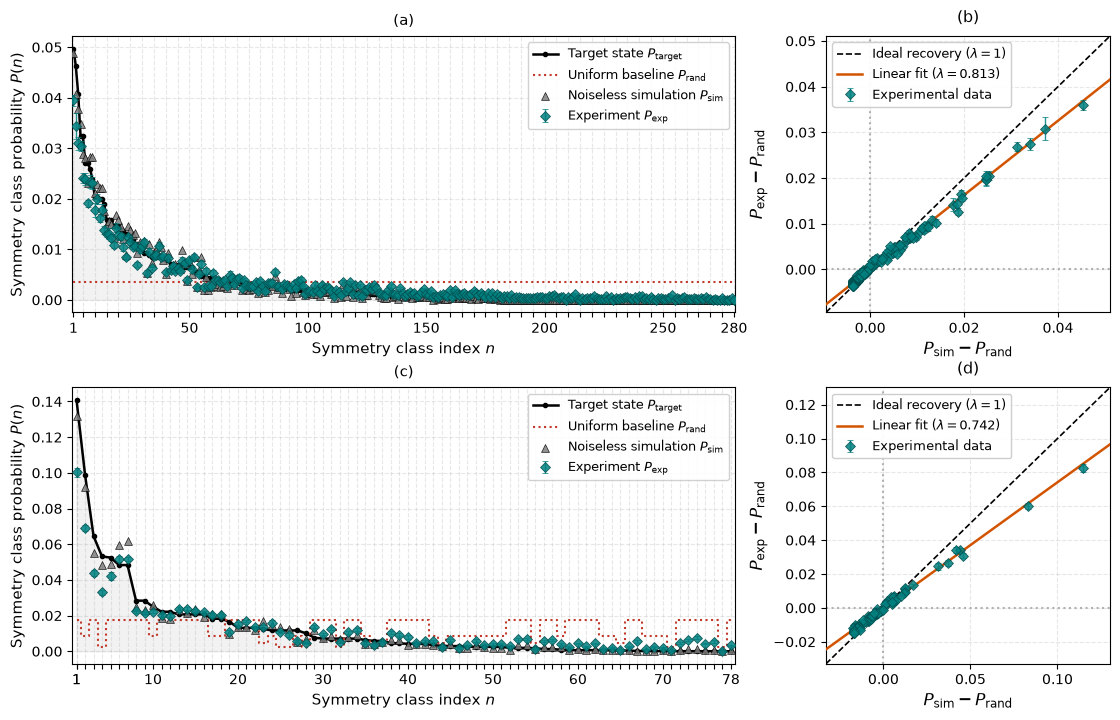

In [ ]:
# Create 1x2 layout
fig, ((ax_00, ax_01), (ax_10, ax_11)) = plt.subplots(2, 2, figsize=(11, 7),gridspec_kw={'width_ratios': [7, 3]})

alpha = 0.85

# Panel (a): 2 Holes, 3 Particles
plot_orbit_distribution(
    metrics=metrics_2h,
    total_shots=shots_2h,
    ax=ax_00,
    title=f"(a)",
    ticks_div=50,
    ticks_no_label = 5,
    alpha=alpha
)

# Panel (b): No Holes, 4 Particles
plot_orbit_distribution(
    metrics=metrics_0h,
    total_shots=shots_0h,
    ax=ax_10,
    title=f"(c)",
    ticks_div=10,
    alpha=alpha
)

plot_symmetry_delta_p_correlation(
        metrics_2h,
        x_axis_mode="noiseless",  # 'noiseless' (or 'ideal') / 'tgt'
        show_fit_stats=True,
        ax=ax_01,
        title="(b)",
        alpha=alpha)

plot_symmetry_delta_p_correlation(
        metrics_0h,
        x_axis_mode="noiseless",  # 'noiseless' (or 'ideal') / 'tgt'
        show_fit_stats=True,
        ax=ax_11,
        title="(d)",
        alpha=alpha)    

plt.tight_layout(pad=0, h_pad=0.2)
# Align y-labels across rows so plot (b) and plot (d) line up nicely
fig.align_ylabels([ax_01, ax_11])
plt.savefig("../figs/fig_population_distributions.pdf", dpi=300, bbox_inches="tight")
plt.show()

# Correlated densities plots

Density grid figure saved to: ../figs/fig_conditional_densities.pdf


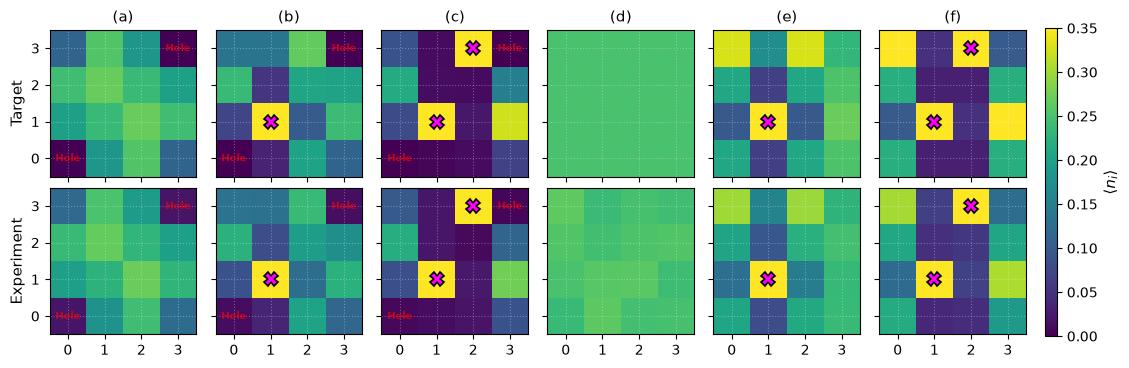

In [ ]:
# Define panel configurations
panels = [
    {
        'counts': counts_2h,
        'psi_tgt': opt_data_2h['psi_tgt'],
        'vList': vList_2h,
        'reference_sites': (),             # 1 Fixed Site
        'preset': 'None',
        'fixed_holes': [(0, 0), (3, 3)],
        'title': "a) 2 holes, N=3"
    },
    {
        'counts': counts_2h,
        'psi_tgt': opt_data_2h['psi_tgt'],
        'vList': vList_2h,
        'reference_sites': (1,1),   # 2 Fixed Sites
        'preset': 'None',
        'fixed_holes': [(0, 0), (3, 3)],
        'title': "b) 2 holes, N=3"
    },
    {
        'counts': counts_2h,
        'psi_tgt': opt_data_2h['psi_tgt'],
        'vList': vList_2h,
        'reference_sites': ((1, 1), (3,2)),   # 2 Fixed Sites
        'preset': 'None',
        'fixed_holes': [(0, 0), (3, 3)],
        'title': "c) 2 holes, N=3",
    },
    {
        'counts': counts_0h,
        'psi_tgt': opt_data_0h['psi_tgt'],
        'vList': vList_0h,
        'reference_sites': (),             # 1 Fixed Site
        'preset': 'None',
        'fixed_holes': [],
        'title' : 'd) No holes, N=4'
    },
    {
        'counts': counts_0h,
        'psi_tgt': opt_data_0h['psi_tgt'],
        'vList': vList_0h,
        'reference_sites': (1,1),             # 1 Fixed Site
        'preset': 'None',
        'fixed_holes': [],
        'title' : 'e) No holes, N=4'
    },
    {
        'counts': counts_0h,
        'psi_tgt': opt_data_0h['psi_tgt'],
        'vList': vList_0h,
        'reference_sites': ((1, 1), (3, 2)),   # 2 Fixed Sites
        'preset': 'None',
        'fixed_holes': [],
        'title' : 'f) No holes, N=4'
    },
]

# Plot the whole row
plot_conditional_density_row(
    panel_specs=panels,
    nodes_sorted=nodes_sorted,
    Ly=Ly, Lx=Lx,
    cmap_choice='viridis',
    output_path="../figs/fig_conditional_densities.pdf",
    vmax_override=0.35
)

# Current plots

### process

In [25]:
filename = "KM_4x4_L_nn_010_2h_p3_50_20260711_012241"
job_list_current = [
    "curr_8-11_DD_4ms_sym",
    "curr_sides_DD_4ms_sym",
    "curr_rest1_DD_4ms_sym",
    "curr_rest2_DD_4ms_sym",
]

job_list_Z = ["DD_4ms_sym_v1", "DD_4ms_sym_v2"]

In [26]:
filename = file_dict["2h"]
dir_path = base_data_dir / filename

opt_data = load_something(filename, directory=dir_path)

psi_tgt = opt_data["psi_tgt"]
dims = opt_data["tgt_info"]["dims"]
vList, _ = generate_boson_base(opt_data["tgt_info"]["N"], dims[0] * dims[1], 1)

nodes_sorted, node_to_idx = get_node_mapping(4, 4)
node_list = [(1,0), (1,1), (0,1), (3,1), (2,1), (2,0), (2,3), (2,2), (3,2), (0,2), (1,2), (1,3)]

result_list = [
    joblib.load(os.path.join(dir_path, f"job_result_{job_name}.pkl"))
    for job_name in job_list_Z
]
counts_per_pub = get_formatted_counts(
    result_list, sum_results=True, sum_pubs=False
)

pairs_label, p_theory, p_exp_mean, p_exp_sem = (
    compute_pair_probabilities_with_uncertainty(
        counts_per_pub, psi_tgt, node_list, node_to_idx, vList, N_target=3
    )
)

idx_list = [node_to_idx[node] for node in node_list]

Ly, Lx = opt_data["gridDims"]
N = opt_data['tgt_info']["N"]
vList, vDic = generate_boson_base(N, Ly * Lx, 1)

phi = 1/2
t_matrix = kapit_mueller_J_matrix(gridGraph((Ly, Lx))[0], phi)

# 2. Merge job files
merged_data_store = load_and_merge_jobs(dir_path, job_list_current)

# 3. Extract experimental currents (nrest2 conditional mode)
exp_currents, exp_errors = extract_loop_currents_exp(
    merged_data_store,
    idx_list,
    t_matrix,
    target_n_particles=3,
    postselect_mode="nrest2",
)

# 1. Scale experimental currents by experimental probabilities
exp_currents = np.array(exp_currents)
exp_errors = np.array(exp_errors)

exp_currents_scaled = exp_currents * p_exp_mean

# 2. Propagate uncertainties using relative error addition in quadrature
# rel_err_total = sqrt( (sigma_I / I)^2 + (sigma_P / P)^2 )
rel_err_currents = np.where(
    exp_currents != 0, np.abs(exp_errors / exp_currents), 0.0
)
rel_err_p = np.where(p_exp_mean != 0, np.abs(p_exp_sem / p_exp_mean), 0.0)

# Total propagated standard error
exp_errors_scaled = (
    np.abs(exp_currents_scaled) * np.sqrt(rel_err_currents**2 + rel_err_p**2)
)
print(f"Average P: {np.mean(p_exp_mean)}")
print("Scaled Currents:", exp_currents_scaled)
print(f"Scaled current sum: {np.sum(exp_currents_scaled)} +- {np.sum(exp_errors_scaled)}")
print("Scaled Errors:  ", exp_errors_scaled)

Successfully merged data across 4 job(s) for 12 bond(s).
Total shots: 240000, post-selected shots: 51350, post-selection rate: 0.21395833333333333
Average P: 0.4183652081101073
Scaled Currents: [-0.00184651 -0.02845196 -0.02219305  0.0042405   0.0022732  -0.04500607
 -0.01627467 -0.02391113 -0.01802416  0.00329411  0.00192394 -0.04166602]
Scaled current sum: -0.18564182228235954 +- 0.05315091015857709
Scaled Errors:   [0.00291244 0.00594306 0.00851463 0.00775685 0.00247753 0.00312837
 0.00451533 0.00395541 0.00496288 0.00376395 0.00188428 0.00333619]


### combine

lambda = 0.624, intercept = 0.00011419483717610673
Total tgt current -0.319, result current -0.300, fidelity 0.9493


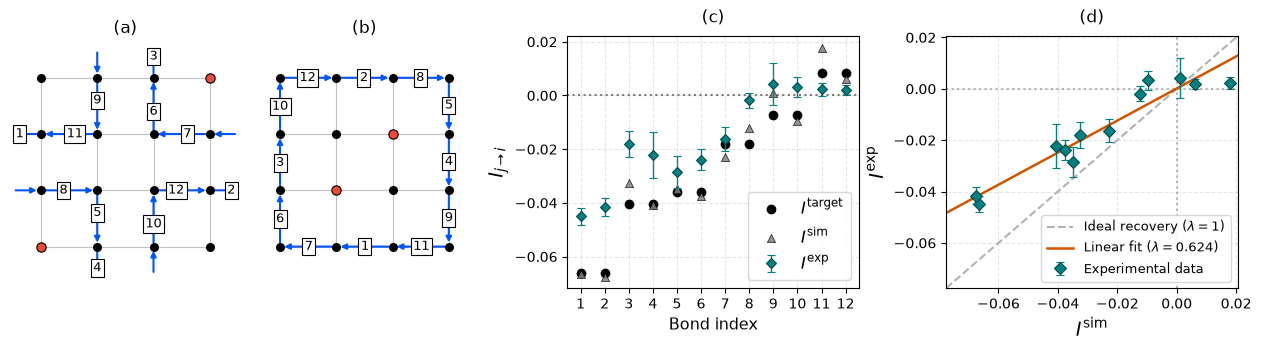

In [27]:
import matplotlib.pyplot as plt

# 1. Use layout="constrained" instead of tight_layout()
# Adjust figsize width/height directly—it will scale predictably now!
fig, axes = plt.subplots(
    1,
    4,
    figsize=(12.5, 3.4),
    gridspec_kw={"width_ratios": [0.95, 0.95, 1.2, 1.2]},
    layout="constrained",
)

# 2. Plot 1: Correlation Scatter Fit
plot_exp_vs_noiseless_scatter(
    ax=axes[3],
    d_theory=opt_data,
    exp_currents=exp_currents_scaled,
    exp_errors=exp_errors_scaled,
    idx_list=idx_list,
    vList=vList,
    vDic=vDic,
    t_matrix=t_matrix,
    fit_line=True,
)

# 3. Plot 2: Bond Current Profile
plot_current_profile(
    ax=axes[2],
    d_theory=opt_data,
    exp_currents=exp_currents_scaled,
    exp_errors=exp_errors_scaled,
    idx_list=idx_list,
    vList=vList,
    vDic=vDic,
    t_matrix=t_matrix,
    show_orthogonal=False,
    order_by_current=True,
)

# 4. Plot 3: Original Lattice Topology
plot_lattice_graph(
    ax=axes[0],
    d_theory=opt_data,
    node_list=node_list,
    idx_list=idx_list,
    vList=vList,
    vDic=vDic,
    t_matrix=t_matrix,
    order_by_current=True,
    node_shrink=3.0,
    badge_shift=0.10,
    shift_offset=(0, 0),
    title="(a)",
)

# 5. Plot 4: Shifted (2,2) Lattice Topology
plot_lattice_graph(
    ax=axes[1],
    d_theory=opt_data,
    node_list=node_list,
    idx_list=idx_list,
    vList=vList,
    vDic=vDic,
    t_matrix=t_matrix,
    order_by_current=True,
    node_shrink=3.0,
    badge_shift=0.01,
    shift_offset=(2, 2),
    title="(b)",
)
plt.savefig("../figs/currents.pdf")
plt.show()